<a href="https://colab.research.google.com/github/bu11ymaguire/SKT_FLY_AI_8/blob/main/12_24_vol4_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [102]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import random

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
np.set_printoptions(precision=4,linewidth=200)

In [103]:
df = pd.read_csv('train.csv')

In [104]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2400 entries, 0 to 2399
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ID                    2400 non-null   int64  
 1   Name                  2400 non-null   object 
 2   Age                   2400 non-null   int64  
 3   Gender                2400 non-null   object 
 4   School_Grade          2400 non-null   object 
 5   Daily_Usage_Hours     2393 non-null   float64
 6   Sleep_Hours           2398 non-null   float64
 7   Academic_Performance  2392 non-null   float64
 8   Exercise_Hours        2397 non-null   float64
 9   Anxiety_Level         2398 non-null   float64
 10  Depression_Level      2394 non-null   float64
 11  Phone_Checks_Per_Day  2395 non-null   float64
 12  Apps_Used_Daily       2400 non-null   int64  
 13  Time_on_Social_Media  2400 non-null   float64
 14  Time_on_Gaming        2400 non-null   float64
 15  Time_on_Education    

In [105]:
print(f"'test_df' 결측치 제거 전 DataFrame의 행 수: {df.shape[0]}")

df.dropna(inplace=True)

print(f"'test_df' 결측치 제거 후 DataFrame의 행 수: {df.shape[0]}")
df.info()

'test_df' 결측치 제거 전 DataFrame의 행 수: 2400
'test_df' 결측치 제거 후 DataFrame의 행 수: 2367
<class 'pandas.core.frame.DataFrame'>
Index: 2367 entries, 0 to 2399
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ID                    2367 non-null   int64  
 1   Name                  2367 non-null   object 
 2   Age                   2367 non-null   int64  
 3   Gender                2367 non-null   object 
 4   School_Grade          2367 non-null   object 
 5   Daily_Usage_Hours     2367 non-null   float64
 6   Sleep_Hours           2367 non-null   float64
 7   Academic_Performance  2367 non-null   float64
 8   Exercise_Hours        2367 non-null   float64
 9   Anxiety_Level         2367 non-null   float64
 10  Depression_Level      2367 non-null   float64
 11  Phone_Checks_Per_Day  2367 non-null   float64
 12  Apps_Used_Daily       2367 non-null   int64  
 13  Time_on_Social_Media  2367 non-null   float64
 1

In [106]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2367 entries, 0 to 2399
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ID                    2367 non-null   int64  
 1   Name                  2367 non-null   object 
 2   Age                   2367 non-null   int64  
 3   Gender                2367 non-null   object 
 4   School_Grade          2367 non-null   object 
 5   Daily_Usage_Hours     2367 non-null   float64
 6   Sleep_Hours           2367 non-null   float64
 7   Academic_Performance  2367 non-null   float64
 8   Exercise_Hours        2367 non-null   float64
 9   Anxiety_Level         2367 non-null   float64
 10  Depression_Level      2367 non-null   float64
 11  Phone_Checks_Per_Day  2367 non-null   float64
 12  Apps_Used_Daily       2367 non-null   int64  
 13  Time_on_Social_Media  2367 non-null   float64
 14  Time_on_Gaming        2367 non-null   float64
 15  Time_on_Education     2367

In [107]:
print("--- 최종 결측치 수 ---")
display(df.isnull().sum())

--- 최종 결측치 수 ---


,0
ID,0
Name,0
Age,0
Gender,0
School_Grade,0
Daily_Usage_Hours,0
Sleep_Hours,0
Academic_Performance,0
Exercise_Hours,0
Anxiety_Level,0


In [108]:
from sklearn.preprocessing import OrdinalEncoder

oe = OrdinalEncoder()
categorical_columns = ['Gender']

df[categorical_columns] = oe.fit_transform(df[categorical_columns])
df.head()

,ID,Name,Age,Gender,School_Grade,Daily_Usage_Hours,Sleep_Hours,Academic_Performance,Exercise_Hours,Anxiety_Level,Depression_Level,Phone_Checks_Per_Day,Apps_Used_Daily,Time_on_Social_Media,Time_on_Gaming,Time_on_Education,Phone_Usage_Purpose,Family_Communication,Addiction_Level
0,1,David Fernandez,17,0.0,7th,3.9,5.8,86.0,2.3,1.0,5.0,66.0,15,1.4,0.2,1.3,Gaming,8,Medium
1,2,Jessica Stevens,19,2.0,9th,5.2,8.7,51.0,1.5,3.0,10.0,81.0,18,2.6,0.1,0.3,Browsing,3,High
2,3,Ricky Fowler,15,1.0,11th,6.7,5.6,78.0,0.9,10.0,8.0,47.0,9,1.7,2.6,2.2,Other,1,High
3,4,Amanda Harris,19,2.0,11th,6.9,7.2,98.0,0.9,4.0,5.0,63.0,10,2.1,1.4,0.9,Browsing,4,High
4,5,Claudia Kelly,17,1.0,12th,4.6,8.9,93.0,1.3,5.0,7.0,44.0,8,1.0,0.8,0.3,Other,4,Medium


In [109]:
df = df.drop(['Name','ID'],axis = 1)
df.head()

,Age,Gender,School_Grade,Daily_Usage_Hours,Sleep_Hours,Academic_Performance,Exercise_Hours,Anxiety_Level,Depression_Level,Phone_Checks_Per_Day,Apps_Used_Daily,Time_on_Social_Media,Time_on_Gaming,Time_on_Education,Phone_Usage_Purpose,Family_Communication,Addiction_Level
0,17,0.0,7th,3.9,5.8,86.0,2.3,1.0,5.0,66.0,15,1.4,0.2,1.3,Gaming,8,Medium
1,19,2.0,9th,5.2,8.7,51.0,1.5,3.0,10.0,81.0,18,2.6,0.1,0.3,Browsing,3,High
2,15,1.0,11th,6.7,5.6,78.0,0.9,10.0,8.0,47.0,9,1.7,2.6,2.2,Other,1,High
3,19,2.0,11th,6.9,7.2,98.0,0.9,4.0,5.0,63.0,10,2.1,1.4,0.9,Browsing,4,High
4,17,1.0,12th,4.6,8.9,93.0,1.3,5.0,7.0,44.0,8,1.0,0.8,0.3,Other,4,Medium


In [110]:
df['Gender'].value_counts()

,count
Gender,
0.0,806
1.0,791
2.0,770


In [111]:
df = df.drop(['Gender'],axis = 1)

In [112]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(sparse_output = False)
onehot_columns = ["Phone_Usage_Purpose"]

In [113]:
pup_encoded_array = ohe.fit_transform(df[onehot_columns])
pup_categories = ohe.get_feature_names_out(onehot_columns)
pup_endocded_df = pd.DataFrame(pup_encoded_array,columns=pup_categories, index=df.index)

In [114]:
if "Phone_Usage_Purpose" in df.columns:
    df = df.drop(columns=onehot_columns)
df = pd.concat([df,pup_endocded_df],axis = 1)
df.head()

,Age,School_Grade,Daily_Usage_Hours,Sleep_Hours,Academic_Performance,Exercise_Hours,Anxiety_Level,Depression_Level,Phone_Checks_Per_Day,Apps_Used_Daily,Time_on_Social_Media,Time_on_Gaming,Time_on_Education,Family_Communication,Addiction_Level,Phone_Usage_Purpose_Browsing,Phone_Usage_Purpose_Education,Phone_Usage_Purpose_Gaming,Phone_Usage_Purpose_Other,Phone_Usage_Purpose_Social Media
0,17,7th,3.9,5.8,86.0,2.3,1.0,5.0,66.0,15,1.4,0.2,1.3,8,Medium,0.0,0.0,1.0,0.0,0.0
1,19,9th,5.2,8.7,51.0,1.5,3.0,10.0,81.0,18,2.6,0.1,0.3,3,High,1.0,0.0,0.0,0.0,0.0
2,15,11th,6.7,5.6,78.0,0.9,10.0,8.0,47.0,9,1.7,2.6,2.2,1,High,0.0,0.0,0.0,1.0,0.0
3,19,11th,6.9,7.2,98.0,0.9,4.0,5.0,63.0,10,2.1,1.4,0.9,4,High,1.0,0.0,0.0,0.0,0.0
4,17,12th,4.6,8.9,93.0,1.3,5.0,7.0,44.0,8,1.0,0.8,0.3,4,Medium,0.0,0.0,0.0,1.0,0.0


In [115]:
# 'School_Grade' 컬럼에서 숫자만 추출
df['School_Grade'] = df['School_Grade'].str.extract('(\d+)').astype(int)

# 변경 확인
display(df.head())
df.info()

<>:2: SyntaxWarning: invalid escape sequence '\d'
<>:2: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipython-input-3503911556.py:2: SyntaxWarning: invalid escape sequence '\d'
  df['School_Grade'] = df['School_Grade'].str.extract('(\d+)').astype(int)


,Age,School_Grade,Daily_Usage_Hours,Sleep_Hours,Academic_Performance,Exercise_Hours,Anxiety_Level,Depression_Level,Phone_Checks_Per_Day,Apps_Used_Daily,Time_on_Social_Media,Time_on_Gaming,Time_on_Education,Family_Communication,Addiction_Level,Phone_Usage_Purpose_Browsing,Phone_Usage_Purpose_Education,Phone_Usage_Purpose_Gaming,Phone_Usage_Purpose_Other,Phone_Usage_Purpose_Social Media
0,17,7,3.9,5.8,86.0,2.3,1.0,5.0,66.0,15,1.4,0.2,1.3,8,Medium,0.0,0.0,1.0,0.0,0.0
1,19,9,5.2,8.7,51.0,1.5,3.0,10.0,81.0,18,2.6,0.1,0.3,3,High,1.0,0.0,0.0,0.0,0.0
2,15,11,6.7,5.6,78.0,0.9,10.0,8.0,47.0,9,1.7,2.6,2.2,1,High,0.0,0.0,0.0,1.0,0.0
3,19,11,6.9,7.2,98.0,0.9,4.0,5.0,63.0,10,2.1,1.4,0.9,4,High,1.0,0.0,0.0,0.0,0.0
4,17,12,4.6,8.9,93.0,1.3,5.0,7.0,44.0,8,1.0,0.8,0.3,4,Medium,0.0,0.0,0.0,1.0,0.0


<class 'pandas.core.frame.DataFrame'>
Index: 2367 entries, 0 to 2399
Data columns (total 20 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Age                               2367 non-null   int64  
 1   School_Grade                      2367 non-null   int64  
 2   Daily_Usage_Hours                 2367 non-null   float64
 3   Sleep_Hours                       2367 non-null   float64
 4   Academic_Performance              2367 non-null   float64
 5   Exercise_Hours                    2367 non-null   float64
 6   Anxiety_Level                     2367 non-null   float64
 7   Depression_Level                  2367 non-null   float64
 8   Phone_Checks_Per_Day              2367 non-null   float64
 9   Apps_Used_Daily                   2367 non-null   int64  
 10  Time_on_Social_Media              2367 non-null   float64
 11  Time_on_Gaming                    2367 non-null   float64
 12  Time_on_Edu

In [116]:
x_train = df.drop(['Addiction_Level'],axis=1)
y_train = df['Addiction_Level']

In [117]:
from sklearn.preprocessing import StandardScaler

xss = StandardScaler()
xss.fit(x_train)

StandardScaler()

In [118]:
x_train_s = xss.transform(x_train)

In [119]:
from sklearn.neighbors import KNeighborsClassifier

In [120]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_neighbors": [3,5,7,9,10,12,14], "weights":["uniform","distance"],
    "p":[1,2]
}

In [121]:
grid_search = GridSearchCV(
    KNeighborsClassifier(), param_grid, cv = 5, scoring="accuracy", refit= True, verbose = 1, n_jobs = -1
)

In [122]:
from sklearn.preprocessing import OrdinalEncoder

oe_y = OrdinalEncoder()

# y_train을 2D 배열로 변환 (fit_transform에 필요)
y_train_encoded = oe_y.fit_transform(y_train.to_frame())

# 인코딩된 y_train을 평탄화 (1D 배열로)
y_train_encoded = y_train_encoded.ravel()

# 인코딩된 값 확인
print("Encoded y_train unique values:", np.unique(y_train_encoded))
print("Original y_train unique values:", y_train.unique())

Encoded y_train unique values: [0. 1. 2.]
Original y_train unique values: ['Medium' 'High' 'Low']


In [123]:
# 변환 후 grid_search.fit 호출
grid_search.fit(x_train_s, y_train_encoded)

Fitting 5 folds for each of 28 candidates, totalling 140 fits


GridSearchCV(cv=5, estimator=KNeighborsClassifier(), n_jobs=-1,
             param_grid={'n_neighbors': [3, 5, 7, 9, 10, 12, 14], 'p': [1, 2],
                         'weights': ['uniform', 'distance']},
             scoring='accuracy', verbose=1)

In [124]:
grid_search.best_score_

np.float64(0.8669191175814668)

In [125]:
model = grid_search.best_estimator_

In [126]:
test_df = pd.read_csv('test.csv')

In [127]:
test_df.isna().sum()

,0
ID,0
Name,0
Age,0
Gender,0
School_Grade,0
Daily_Usage_Hours,2
Sleep_Hours,1
Academic_Performance,1
Exercise_Hours,0
Anxiety_Level,0


In [128]:
print(f"'test_df' 결측치 제거 전 DataFrame의 행 수: {test_df.shape[0]}")

test_df.dropna(inplace=True)

print(f"'test_df' 결측치 제거 후 DataFrame의 행 수: {test_df.shape[0]}")
test_df.info()

'test_df' 결측치 제거 전 DataFrame의 행 수: 600
'test_df' 결측치 제거 후 DataFrame의 행 수: 593
<class 'pandas.core.frame.DataFrame'>
Index: 593 entries, 0 to 599
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ID                    593 non-null    int64  
 1   Name                  593 non-null    object 
 2   Age                   593 non-null    int64  
 3   Gender                593 non-null    object 
 4   School_Grade          593 non-null    object 
 5   Daily_Usage_Hours     593 non-null    float64
 6   Sleep_Hours           593 non-null    float64
 7   Academic_Performance  593 non-null    float64
 8   Exercise_Hours        593 non-null    float64
 9   Anxiety_Level         593 non-null    int64  
 10  Depression_Level      593 non-null    float64
 11  Phone_Checks_Per_Day  593 non-null    int64  
 12  Apps_Used_Daily       593 non-null    int64  
 13  Time_on_Social_Media  593 non-null    float64
 14  T

In [129]:
test_df.drop(['Gender'],axis=1)

,ID,Name,Age,School_Grade,Daily_Usage_Hours,Sleep_Hours,Academic_Performance,Exercise_Hours,Anxiety_Level,Depression_Level,Phone_Checks_Per_Day,Apps_Used_Daily,Time_on_Social_Media,Time_on_Gaming,Time_on_Education,Phone_Usage_Purpose,Family_Communication,Addiction_Level
0,2500,Alisha Howard,14,10th,4.1,6.6,57.0,1.3,4,6.0,95,5,1.5,0.0,0.6,Social Media,2,Medium
1,2501,Martin Hammond,16,8th,5.8,7.6,87.0,1.1,10,1.0,71,8,2.3,0.6,2.7,Other,4,High
2,2502,Richard Li,19,7th,1.2,8.1,89.0,0.7,2,9.0,148,15,1.7,3.3,0.9,Gaming,9,High
3,2503,Michael Smith,14,12th,6.8,3.6,86.0,0.3,3,1.0,145,13,3.3,1.5,0.5,Gaming,9,High
4,2504,Christina Combs,18,12th,3.9,8.2,97.0,0.3,2,4.0,35,19,2.1,0.0,1.0,Browsing,4,Medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
595,3095,Ruben Walters,14,11th,1.6,5.9,70.0,1.5,10,8.0,147,18,1.9,2.7,1.0,Browsing,7,High
596,3096,Wesley Carey,19,7th,4.1,6.9,92.0,0.8,1,2.0,39,13,1.5,3.2,1.4,Gaming,3,High
597,3097,Jeffrey Dunn,19,12th,2.0,7.9,99.0,1.7,10,8.0,103,8,3.2,0.0,2.1,Browsing,8,Medium
598,3098,Kathryn Romero,17,8th,3.8,6.3,65.0,0.3,1,5.0,83,18,3.1,3.7,0.9,Browsing,2,High


In [130]:
pup_encoded_array = ohe.fit_transform(test_df[onehot_columns])
pup_categories = ohe.get_feature_names_out(onehot_columns)
pup_endocded_df = pd.DataFrame(pup_encoded_array,columns=pup_categories, index=test_df.index)

In [131]:
if "Phone_Usage_Purpose" in test_df.columns:
    test_df = test_df.drop(columns=onehot_columns)
test_df = pd.concat([test_df,pup_endocded_df],axis = 1)
test_df.head()

,ID,Name,Age,Gender,School_Grade,Daily_Usage_Hours,Sleep_Hours,Academic_Performance,Exercise_Hours,Anxiety_Level,...,Time_on_Social_Media,Time_on_Gaming,Time_on_Education,Family_Communication,Addiction_Level,Phone_Usage_Purpose_Browsing,Phone_Usage_Purpose_Education,Phone_Usage_Purpose_Gaming,Phone_Usage_Purpose_Other,Phone_Usage_Purpose_Social Media
0,2500,Alisha Howard,14,Other,10th,4.1,6.6,57.0,1.3,4,...,1.5,0.0,0.6,2,Medium,0.0,0.0,0.0,0.0,1.0
1,2501,Martin Hammond,16,Female,8th,5.8,7.6,87.0,1.1,10,...,2.3,0.6,2.7,4,High,0.0,0.0,0.0,1.0,0.0
2,2502,Richard Li,19,Male,7th,1.2,8.1,89.0,0.7,2,...,1.7,3.3,0.9,9,High,0.0,0.0,1.0,0.0,0.0
3,2503,Michael Smith,14,Male,12th,6.8,3.6,86.0,0.3,3,...,3.3,1.5,0.5,9,High,0.0,0.0,1.0,0.0,0.0
4,2504,Christina Combs,18,Male,12th,3.9,8.2,97.0,0.3,2,...,2.1,0.0,1.0,4,Medium,1.0,0.0,0.0,0.0,0.0


In [132]:
# 'School_Grade' 컬럼에서 숫자만 추출
test_df['School_Grade'] = test_df['School_Grade'].str.extract('(\d+)').astype(int)

# 변경 확인
display(test_df.head())
test_df.info()

<>:2: SyntaxWarning: invalid escape sequence '\d'
<>:2: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipython-input-3735409421.py:2: SyntaxWarning: invalid escape sequence '\d'
  test_df['School_Grade'] = test_df['School_Grade'].str.extract('(\d+)').astype(int)


,ID,Name,Age,Gender,School_Grade,Daily_Usage_Hours,Sleep_Hours,Academic_Performance,Exercise_Hours,Anxiety_Level,...,Time_on_Social_Media,Time_on_Gaming,Time_on_Education,Family_Communication,Addiction_Level,Phone_Usage_Purpose_Browsing,Phone_Usage_Purpose_Education,Phone_Usage_Purpose_Gaming,Phone_Usage_Purpose_Other,Phone_Usage_Purpose_Social Media
0,2500,Alisha Howard,14,Other,10,4.1,6.6,57.0,1.3,4,...,1.5,0.0,0.6,2,Medium,0.0,0.0,0.0,0.0,1.0
1,2501,Martin Hammond,16,Female,8,5.8,7.6,87.0,1.1,10,...,2.3,0.6,2.7,4,High,0.0,0.0,0.0,1.0,0.0
2,2502,Richard Li,19,Male,7,1.2,8.1,89.0,0.7,2,...,1.7,3.3,0.9,9,High,0.0,0.0,1.0,0.0,0.0
3,2503,Michael Smith,14,Male,12,6.8,3.6,86.0,0.3,3,...,3.3,1.5,0.5,9,High,0.0,0.0,1.0,0.0,0.0
4,2504,Christina Combs,18,Male,12,3.9,8.2,97.0,0.3,2,...,2.1,0.0,1.0,4,Medium,1.0,0.0,0.0,0.0,0.0


<class 'pandas.core.frame.DataFrame'>
Index: 593 entries, 0 to 599
Data columns (total 23 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   ID                                593 non-null    int64  
 1   Name                              593 non-null    object 
 2   Age                               593 non-null    int64  
 3   Gender                            593 non-null    object 
 4   School_Grade                      593 non-null    int64  
 5   Daily_Usage_Hours                 593 non-null    float64
 6   Sleep_Hours                       593 non-null    float64
 7   Academic_Performance              593 non-null    float64
 8   Exercise_Hours                    593 non-null    float64
 9   Anxiety_Level                     593 non-null    int64  
 10  Depression_Level                  593 non-null    float64
 11  Phone_Checks_Per_Day              593 non-null    int64  
 12  Apps_Used_Dai

In [133]:
x_test = test_df.drop(['Addiction_Level','Gender','Name','ID'],axis=1)
y_test = test_df['Addiction_Level']

In [134]:
x_test_s = xss.transform(x_test)

In [135]:
y_test = oe_y.fit_transform(y_test.to_frame())

In [136]:
y_pred = model.predict(x_test_s)

In [145]:
from sklearn.metrics import accuracy_score,precision_score
from sklearn.metrics import recall_score,f1_score
from sklearn.metrics import confusion_matrix

def print_metrics(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    pre = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    recall = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)

    print(f"정확도 {acc}")
    print(f"정밀도 {pre}")
    print(f"재현율 {recall}")
    print(f"f1 {f1}")

    cfm = confusion_matrix(y_true,y_pred)

    s = sns.heatmap( cfm,annot=True, fmt='d',cbar=False )
    s.set( xlabel='Prediction',ylabel='Actual')
    plt.show()

정확도 0.866779089376054
정밀도 0.8271234155850609
재현율 0.866779089376054
f1 0.8214058788469493


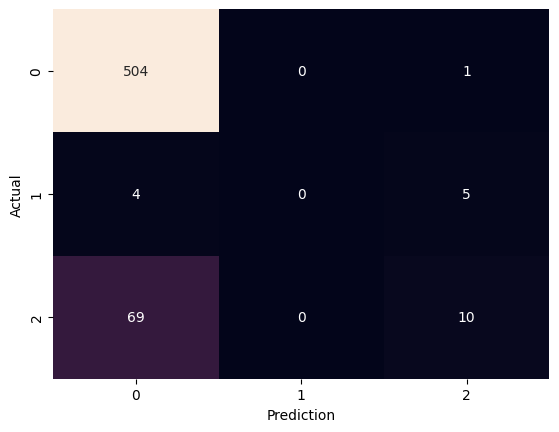

In [146]:
print_metrics(y_test, y_pred)

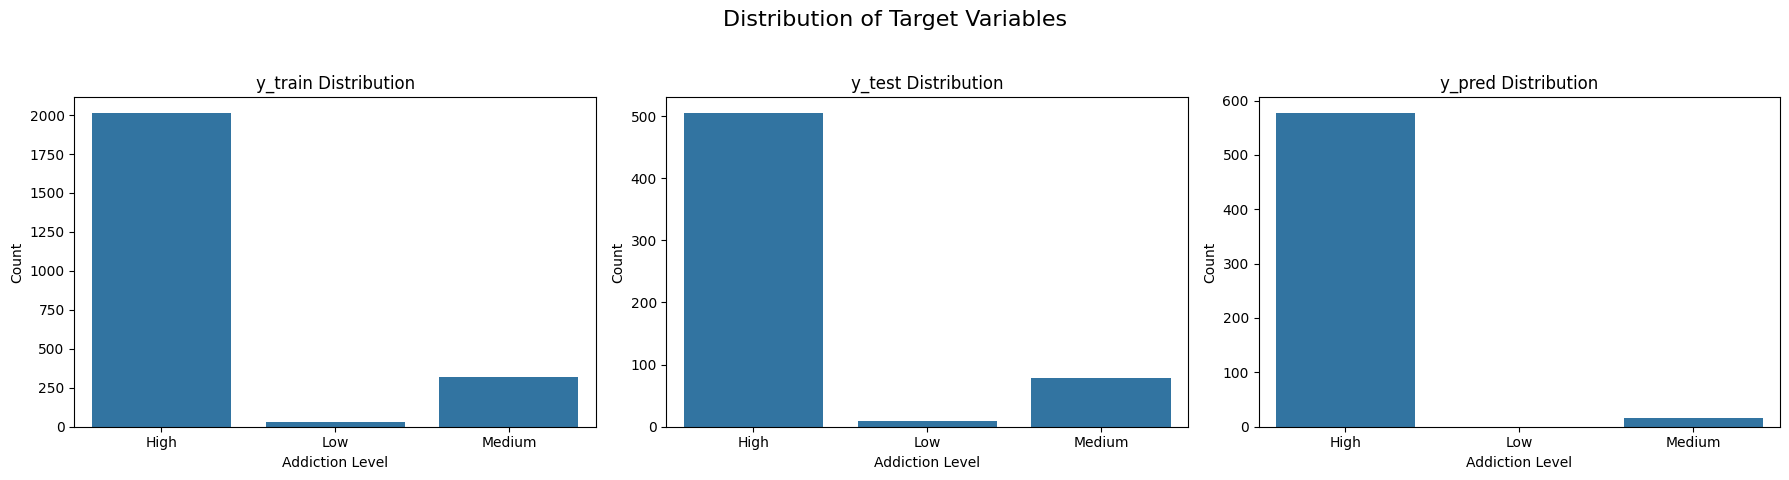

In [147]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# y_train_encoded, y_test (raveled), y_pred의 분포를 Pandas Series로 변환 (value_counts 사용)
# oe_y.inverse_transform을 사용하여 원본 레이블로 다시 변환합니다.

y_train_original_labels = oe_y.inverse_transform(y_train_encoded.reshape(-1, 1)).ravel()
y_test_original_labels = oe_y.inverse_transform(y_test).ravel()
y_pred_original_labels = oe_y.inverse_transform(y_pred.reshape(-1, 1)).ravel()


# 분포 시각화
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Distribution of Target Variables', fontsize=16)

# y_train 분포
sns.countplot(x=y_train_original_labels, ax=axes[0], order=oe_y.categories_[0])
axes[0].set_title('y_train Distribution')
axes[0].set_xlabel('Addiction Level')
axes[0].set_ylabel('Count')

# y_test 분포
sns.countplot(x=y_test_original_labels, ax=axes[1], order=oe_y.categories_[0])
axes[1].set_title('y_test Distribution')
axes[1].set_xlabel('Addiction Level')
axes[1].set_ylabel('Count')

# y_pred 분포
sns.countplot(x=y_pred_original_labels, ax=axes[2], order=oe_y.categories_[0])
axes[2].set_title('y_pred Distribution')
axes[2].set_xlabel('Addiction Level')
axes[2].set_ylabel('Count')

plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent suptitle overlap
plt.show()